# 多クラス分類と多ラベル分類（評価指標と訓練 CV による閾値選択）

書籍 第2章「分類・回帰問題の解き方」（2-2 文書分類：2-2-1 タスク、練習問題 2）に対応する演習ノートブックです。
CPU のみ・数秒で実行でき、1 つの文書に複数のカテゴリが同時に付きうる**多ラベル分類**（multi-label classification）の仕組みと評価尺度を体験します。

1. **重複なしデータでの訓練・交差検証**: 24 件の重複しないニュース見出しで 4 分割 CV を実施し、Micro-F1 を最大化する閾値を選択
2. **多クラス分類（Top-1）vs 多ラベル分類の比較**: 標準閾値 `0.50` と訓練 CV 選択閾値をテストデータで比較
3. **評価指標の違い**: Subset Accuracy（完全一致）と Hamming Loss / Micro-F1 / Macro-F1 / Samples-F1 の違い
4. **ラベル間の共起関係 (Classifier Chains) とラベル別閾値最適化**（2-2-1 発展）: 条件付き共起確率 $P(y_j=1 \mid y_i=1)$、ラベル別 CV 閾値とゼロ予測フォールバック、およびラベル依存が強い場合の `Ensemble of Classifier Chains (ECC)` による救済

In [1]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, hamming_loss
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MultiLabelBinarizer

---

## 1. サンプルデータと訓練 CV による閾値選択

書籍 2-2-1（p.59）の「元オリンピック選手が参議院に立候補する → スポーツ＋政治」のように、ニュース記事には複数のラベルが同時に付くことがあります。
ここでは `政治`・`経済`・`スポーツ`・`IT` の 4 カテゴリをバランスよく含む **重複のない 24 件の訓練見出し** と **8 件のテスト見出し** を用意し、テストデータを見ずに **訓練データの 4 分割交差検証（`cross_val_predict`）** だけで最適な出力閾値 `best_th` を選びます（同一事例を複数回複製すると CV でフォールド間リークが起きるため、すべて異なる見出しを使います）。

In [2]:
train_samples = [
    ("首相が来年度の税制改正案と経済対策について国会で所信表明を行った", ["政治", "経済"]),
    ("中央銀行が政策金利の据え置きを決定し、円相場と株価が反応した", ["経済"]),
    ("与党と野党が補正予算案の審議日程をめぐって協議を続けた", ["政治"]),
    ("生成AIの規制に関する新たな政府ガイドラインと法案が国会に提出された", ["政治", "IT"]),
    ("大手IT企業がクラウド基盤と半導体製造へ巨額の設備投資を発表した", ["経済", "IT"]),
    ("元オリンピック金メダリストが夏の参議院選挙への立候補を表明した", ["政治", "スポーツ"]),
    ("プロ野球の開幕戦が満員の球場で開催され新人が決勝打を放った", ["スポーツ"]),
    ("スポーツ庁がAIを活用した選手データ分析の推進事業を予算化した", ["政治", "スポーツ", "IT"]),
    ("国内スタートアップが新しい大規模言語モデルの商用APIを公開した", ["経済", "IT"]),
    ("サッカー日本代表の国際親善試合でスポンサー企業の株価が上昇した", ["経済", "スポーツ"]),
    ("政府がデジタル庁のシステム刷新に向けたサイバーセキュリティ対策を強化", ["政治", "IT"]),
    ("大手自動車メーカーが自動運転ソフトウェア開発企業を買収し決算が増益", ["経済", "IT"]),
    ("陸上世界選手権の代表選考会が国立競技場で開かれ日本新記録が出た", ["スポーツ"]),
    ("自治体がプロスポーツチームと連携した地域経済活性化策を発表した", ["政治", "経済", "スポーツ"]),
    ("新興テック企業の資金調達額が前年比2倍となり市場の注目を集めた", ["経済", "IT"]),
    ("元プロサッカー選手がスポーツ振興担当の議員連盟で講演した", ["政治", "スポーツ"]),
    ("ソフトウェア開発企業各社がクラウド基盤と生成AIの新サービスを公開した", ["IT"]),
    ("衆議院の総選挙に向けた各党の公約と国会での外交法案が議論された", ["政治"]),
    ("政府が半導体投資と物価対策に向けた新たな経済支援策を決定した", ["政治", "経済"]),
    ("プロ野球とサッカーの新規スポンサー契約により球団経営の収益が拡大した", ["経済", "スポーツ"]),
    ("IT企業が競技用AIカメラとデータ配信システムを全国大会へ導入した", ["スポーツ", "IT"]),
    ("政府が行政システムのクラウド移行とサイバーセキュリティ法案を提出した", ["政治", "IT"]),
    ("企業の決算発表で半導体や自動車株が買われ市場の株価が上昇した", ["経済"]),
    ("世界水泳の代表選考会で日本選手団が新記録を出し五輪代表に決まった", ["スポーツ"]),
]

test_samples = [
    ("元五輪選手が国会でスポーツ予算と経済効果について質問に立った", ["政治", "経済", "スポーツ"]),
    ("政府がAIスタートアップへの補助金と規制緩和の新政策を決定した", ["政治", "経済", "IT"]),
    ("国内IT大手がプロ野球球団の放映権ビジネスで増収を達成した", ["経済", "スポーツ", "IT"]),
    ("サイバー攻撃対策の新法案が参議院本会議で可決された", ["政治", "IT"]),
    ("半導体大手の四半期決算が過去最高益となり市場で買いが広がった", ["経済", "IT"]),
    ("プロ野球とサッカー日本代表の国際試合が国立競技場で開催された", ["スポーツ"]),
    ("衆議院本会議で新年度予算案の採決と物価高対策が議論された", ["政治", "経済"]),
    ("IT各社が新しい生成AI基盤モデルとクラウド開発環境を発表した", ["IT"]),
]

mlb = MultiLabelBinarizer(classes=["政治", "経済", "スポーツ", "IT"])
train_texts = [txt for txt, _ in train_samples]
test_texts = [txt for txt, _ in test_samples]
Y_train = mlb.fit_transform([lbls for _, lbls in train_samples])
Y_test = mlb.transform([lbls for _, lbls in test_samples])

print("訓練データ件数:", len(train_samples), "| ラベル出現数:", dict(zip(mlb.classes_, Y_train.sum(axis=0).tolist())))
print("テストデータ件数:", len(test_samples), "| ラベル出現数:", dict(zip(mlb.classes_, Y_test.sum(axis=0).tolist())))

# パイプライン化することで CV の各フォールド内で TF-IDF を学習し、リークを防ぐ
pipe = make_pipeline(
    TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 3)),
    OneVsRestClassifier(LogisticRegression(max_iter=1000, C=5.0)),
)

cv = KFold(n_splits=4, shuffle=True, random_state=42)
oof_probs = cross_val_predict(pipe, train_texts, Y_train, cv=cv, method="predict_proba")

candidates = np.round(np.arange(0.20, 0.61, 0.05), 2)
cv_rows = []
for th in candidates:
    Y_oof = (oof_probs >= th).astype(int)
    cv_rows.append({
        "閾値": float(th),
        "訓練CV Micro-F1": round(f1_score(Y_train, Y_oof, average="micro", zero_division=0), 3),
        "訓練CV Samples-F1": round(f1_score(Y_train, Y_oof, average="samples", zero_division=0), 3),
    })

cv_df = pd.DataFrame(cv_rows)
best_th = float(cv_df.loc[cv_df["訓練CV Micro-F1"].idxmax(), "閾値"])
print(f"\n4-fold CV で選ばれた閾値: best_th = {best_th:.2f}")
display(cv_df)

# 全訓練データで再学習し、テストデータの予測確率を得る
pipe.fit(train_texts, Y_train)
probs = pipe.predict_proba(test_texts)

訓練データ件数: 24 | ラベル出現数: {'政治': 11, '経済': 11, 'スポーツ': 10, 'IT': 10}
テストデータ件数: 8 | ラベル出現数: {'政治': 4, '経済': 5, 'スポーツ': 3, 'IT': 5}

4-fold CV で選ばれた閾値: best_th = 0.35


,閾値,訓練CV Micro-F1,訓練CV Samples-F1
0,0.20,0.609,0.594
1,0.25,0.607,0.594
2,0.30,0.624,0.610
3,0.35,0.661,0.655
4,0.40,0.660,0.659
5,0.45,0.625,0.617
6,0.50,0.559,0.517
7,0.55,0.370,0.340
8,0.60,0.213,0.167


---

## 2. 多クラス（Top-1）vs 多ラベル分類と評価指標の比較

テストデータ上で次の 3 手法を比較します。
1. **多クラス分類（Top-1：最大確率 1 ラベルのみ）**: 1 文書につき最も確率の高い 1 ラベルだけを出力した場合の振る舞い
2. **多ラベル分類（標準閾値 `0.50`）**: 各ラベル独立の 2 値分類器に既定の閾値 `0.50` を適用
3. **多ラベル分類（訓練 CV で選んだ閾値）**: 訓練 CV の Micro-F1 が最大となった `best_th` を適用

評価時には **Subset Accuracy（全ラベルが完全一致した割合）** は 1 つでも過不足があると 0 点になるため非常に厳しく、**Hamming Loss** や **Micro-F1 / Macro-F1 / Samples-F1** をあわせて確認します。

In [3]:
def eval_multilabel(name, Y_true, Y_pred):
    return {
        "手法": name,
        "Subset Accuracy": round(accuracy_score(Y_true, Y_pred), 3),
        "Hamming Loss": round(hamming_loss(Y_true, Y_pred), 3),
        "Micro-F1": round(f1_score(Y_true, Y_pred, average="micro", zero_division=0), 3),
        "Macro-F1": round(f1_score(Y_true, Y_pred, average="macro", zero_division=0), 3),
        "Samples-F1": round(f1_score(Y_true, Y_pred, average="samples", zero_division=0), 3),
    }

Y_top1 = np.zeros_like(Y_test)
Y_top1[np.arange(len(probs)), np.argmax(probs, axis=1)] = 1
Y_050 = (probs >= 0.50).astype(int)
Y_best = (probs >= best_th).astype(int)

summary_df = pd.DataFrame([
    eval_multilabel("多クラス分類（Top-1：最大確率 1 ラベルのみ）", Y_test, Y_top1),
    eval_multilabel("多ラベル分類（標準閾値 0.50）", Y_test, Y_050),
    eval_multilabel(f"多ラベル分類（訓練 CV で選んだ閾値 {best_th:.2f}）", Y_test, Y_best),
])
display(summary_df)

# 各見出しでの Top-1 予測 vs 訓練 CV 閾値での多ラベル予測と各ラベル確率
rows = []
for (txt, gold), p_row, top1_bin, best_bin in zip(test_samples, probs, Y_top1, Y_best):
    top1_lbls = [c for c, flag in zip(mlb.classes_, top1_bin) if flag]
    best_lbls = [c for c, flag in zip(mlb.classes_, best_bin) if flag]
    rows.append({
        "見出し": txt[:24] + "...",
        "正解ラベル": ",".join(gold),
        "Top-1予測": ",".join(top1_lbls),
        f"多ラベル予測(閾値{best_th:.2f})": ",".join(best_lbls),
        **{f"P({c})": round(float(p), 2) for c, p in zip(mlb.classes_, p_row)},
    })
pd.DataFrame(rows)

,手法,Subset Accuracy,Hamming Loss,Micro-F1,Macro-F1,Samples-F1
0,多クラス分類（Top-1：最大確率 1 ラベルのみ）,0.25,0.281,0.640,0.610,0.688
1,多ラベル分類（標準閾値 0.50）,0.25,0.219,0.741,0.735,0.762
2,多ラベル分類（訓練 CV で選んだ閾値 0.35）,0.50,0.125,0.889,0.904,0.857


,見出し,正解ラベル,Top-1予測,多ラベル予測(閾値0.35),P(政治),P(経済),P(スポーツ),P(IT)
0,元五輪選手が国会でスポーツ予算と経済効果について...,"政治,経済,スポーツ",政治,"政治,経済,スポーツ",0.66,0.43,0.50,0.25
1,政府がAIスタートアップへの補助金と規制緩和の新...,"政治,経済,IT",経済,"政治,経済,IT",0.50,0.58,0.27,0.47
2,国内IT大手がプロ野球球団の放映権ビジネスで増収...,"経済,スポーツ,IT",経済,"政治,経済,スポーツ,IT",0.37,0.54,0.52,0.35
3,サイバー攻撃対策の新法案が参議院本会議で可決され...,"政治,IT",政治,"政治,IT",0.66,0.28,0.30,0.44
4,半導体大手の四半期決算が過去最高益となり市場で買...,"経済,IT",経済,"経済,IT",0.31,0.62,0.29,0.44
5,プロ野球とサッカー日本代表の国際試合が国立競技場...,スポーツ,スポーツ,"経済,スポーツ",0.25,0.43,0.74,0.19
6,衆議院本会議で新年度予算案の採決と物価高対策が議...,"政治,経済",政治,政治,0.67,0.33,0.26,0.27
7,IT各社が新しい生成AI基盤モデルとクラウド開発...,IT,IT,"経済,IT",0.33,0.48,0.29,0.65


- **Top-1（単一ラベル強制）の限界**: 複合トピックの見出しでも 1 ラベルしか出力できないため、単一ラベルの見出し 2 件（`スポーツ`・`IT`）以外で必ず取りこぼしが生じ、Subset Accuracy は `0.250`、Micro-F1 は `0.640` に留まります。
- **標準閾値 `0.50` と訓練 CV 閾値 `0.35` の違い**: One-vs-Rest の各 2 値分類器では正例が少数派になりやすいため、副次ラベルの予測確率が `0.40〜0.48` 程度に留まる事例が多く、`0.50` では再現率が伸びません（Micro-F1 `0.741`）。テストデータを見ずに訓練データの 4 分割 CV だけで選んだ閾値 `0.35` を使うと、Micro-F1 が `0.889`（Samples-F1 `0.857`、Hamming Loss `0.125`）まで改善します。
- **閾値を下げるトレードオフ**: 一方で閾値を `0.35` に下げると、「国内IT大手がプロ野球球団の...」に `政治`（`P=0.37`）が追加されるなど偽陽性が増えるケースもあり、再現率と適合率のバランスを目的に応じて開発・CV データで調整する重要性がわかります。

---

## 3. ラベル間の共起関係 (Classifier Chains) とラベル別閾値最適化（2-2-1 発展）

第 2 節では 4 つのラベルに共通の閾値 `best_th = 0.35` を適用し、各ラベルを独立に予測する `OneVsRestClassifier` を評価しました。しかし実務の多ラベル分類では、次の 2 点が重要になります。

1. **ラベル別閾値とゼロ予測フォールバック**: ラベルごとに正例率や単語の散らばり方が異なるため、共通閾値では偽陽性が多いラベル（`経済` など）と再現率を重視したいラベル（`IT` など）を同時に最適化できません。訓練 CV の予測確率 (`oof_probs`) で**ラベルごとの最適閾値 $\theta_c$** を決め、さらに全ラベルが閾値未満になる事例には**最大確率ラベルを 1 つ補うゼロ予測フォールバック**を導入します。
2. **ラベル間の共起関係と Classifier Chains**: あるラベルが成立すると別のラベルも同時に成立しやすい（または排反になる）場合、前のラベルの予測結果を次の分類器の素性へ連結する **Classifier Chain**、および順序依存を平均化する **Ensemble of Classifier Chains (ECC)** (Read et al., 2011) が有効です。

ここではまず訓練データの条件付き共起確率 $P(\text{Col} \mid \text{Row})$ を確認したうえで、既存のテスト 8 件および難しい見出しを加えた拡張テスト 16 件で比較し、さらにラベル共起が強い運用インシデント分類のストレステストで ECC の威力を確かめます。

In [4]:
from itertools import permutations

import matplotlib.pyplot as plt
from sklearn.multioutput import ClassifierChain

# 1. 訓練データの条件付き共起確率 P(Col = 1 | Row = 1)
cooc_counts = Y_train.T @ Y_train
cond_cooc = cooc_counts / Y_train.sum(axis=0)[:, None]
cond_df = pd.DataFrame(cond_cooc.round(3), index=mlb.classes_, columns=mlb.classes_)
print("=== 実験 3-1: 訓練データ（24件）の条件付き共起確率 P(Col | Row) ===")
display(cond_df)

# 2. ラベル別 CV 閾値の探索（テストデータは一切見ずに oof_probs のみ使用）
th_grid = np.round(np.arange(0.20, 0.71, 0.05), 2)
per_label_th = []
for j, cname in enumerate(mlb.classes_):
    scores = [f1_score(Y_train[:, j], (oof_probs[:, j] >= t).astype(int), zero_division=0) for t in th_grid]
    per_label_th.append(float(th_grid[int(np.argmax(scores))]))
per_label_th_arr = np.array(per_label_th)
print("訓練 CV で学習したラベル別閾値:", dict(zip(mlb.classes_, per_label_th)))

def apply_thresholds_with_fallback(prob_mat, thresholds):
    Y_raw = (prob_mat >= thresholds).astype(int)
    zero_count = int((Y_raw.sum(axis=1) == 0).sum())
    Y_out = Y_raw.copy()
    for idx in np.where(Y_out.sum(axis=1) == 0)[0]:
        Y_out[idx, np.argmax(prob_mat[idx])] = 1
    return Y_out, zero_count

# 3. Ensemble of Classifier Chains (ECC: 全 4! = 24 通りの順序を平均)
vec_news = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 3))
X_tr_news = vec_news.fit_transform(train_texts)
X_te_news = vec_news.transform(test_texts)

oof_ecc = np.zeros_like(oof_probs)
for tr_idx, va_idx in cv.split(train_texts):
    v_f = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 3))
    X_ftr = v_f.fit_transform([train_texts[i] for i in tr_idx])
    X_fva = v_f.transform([train_texts[i] for i in va_idx])
    p_fold = np.zeros((len(va_idx), Y_train.shape[1]))
    for order in permutations(range(Y_train.shape[1])):
        cc = ClassifierChain(LogisticRegression(max_iter=1000, C=5.0), order=list(order), cv=4, chain_method="predict", random_state=42)
        cc.fit(X_ftr, Y_train[tr_idx])
        p_fold += cc.predict_proba(X_fva)
    oof_ecc[va_idx] = p_fold / 24.0

ecc_per_th = np.array([
    float(th_grid[int(np.argmax([f1_score(Y_train[:, j], (oof_ecc[:, j] >= t).astype(int), zero_division=0) for t in th_grid]))])
    for j in range(Y_train.shape[1])
])

p_ecc_8 = np.zeros_like(probs)
for order in permutations(range(Y_train.shape[1])):
    cc = ClassifierChain(LogisticRegression(max_iter=1000, C=5.0), order=list(order), cv=4, chain_method="predict", random_state=42)
    cc.fit(X_tr_news, Y_train)
    p_ecc_8 += cc.predict_proba(X_te_news)
p_ecc_8 /= 24.0

def eval_strategy(name, Y_true, prob_mat, th, fallback=True):
    Y_raw = (prob_mat >= th).astype(int)
    zero_raw = int((Y_raw.sum(axis=1) == 0).sum())
    if fallback:
        Y_pred, _ = apply_thresholds_with_fallback(prob_mat, th)
    else:
        Y_pred = Y_raw
    row = eval_multilabel(name, Y_true, Y_pred)
    row["ゼロ予測件数(補正前)"] = zero_raw
    return row, Y_pred

r_ovr_050_8, _ = eval_strategy("OneVsRest（標準閾値 0.50）", Y_test, probs, 0.50, fallback=False)
r_ovr_com_8, _ = eval_strategy(f"OneVsRest（訓練 CV 共通閾値 {best_th:.2f}）", Y_test, probs, best_th, fallback=False)
r_ovr_per_8, Y_per_8 = eval_strategy("OneVsRest（訓練 CV ラベル別閾値 + フォールバック）", Y_test, probs, per_label_th_arr, fallback=True)
r_ecc_per_8, Y_ecc_8 = eval_strategy("Ensemble of Classifier Chains (ECC・ラベル別 CV)", Y_test, p_ecc_8, ecc_per_th, fallback=True)

print("\n=== テスト 8 件での手法比較 ===")
comp_8_df = pd.DataFrame([r_ovr_050_8, r_ovr_com_8, r_ovr_per_8, r_ecc_per_8])
display(comp_8_df)

# 共通閾値 0.35 からラベル別閾値で変化した具体例
print("=== 共通閾値 0.35 -> ラベル別閾値での予測変化（テスト 8 件） ===")
for i, ((txt, gold), p_row, y_com, y_per) in enumerate(zip(test_samples, probs, Y_best, Y_per_8)):
    if not np.array_equal(y_com, y_per):
        lbl_com = [c for c, f in zip(mlb.classes_, y_com) if f]
        lbl_per = [c for c, f in zip(mlb.classes_, y_per) if f]
        tag = "[改善・完全一致]" if lbl_per == sorted(gold, key=lambda x: list(mlb.classes_).index(x)) else "[取りこぼし]"
        print(f"  {tag} [#{i}] {txt[:26]}... | 正解={gold} | 0.35={lbl_com} -> ラベル別={lbl_per} | P={np.round(p_row, 2)}")

# 4. 拡張 16 件テストスイート（ゼロ予測を起こす短い・間接的な見出しを追加）
hard_test_samples = [
    ("地方の首長選挙が告示され各陣営が街頭演説を始めた", ["政治"]),
    ("全国高校駅伝の都大路レースで最終区間の逆転劇が起きた", ["スポーツ"]),
    ("オープンソースの機械学習ライブラリ最新版が公開された", ["IT"]),
    ("財務省が国債発行計画と金利動向の見通しを公表した", ["政治", "経済"]),
    ("プロ野球球団が観客動員予測の最適化システムを導入した", ["スポーツ", "IT"]),
    ("首相が国内半導体工場への補助金拡充とデジタル投資方針を表明した", ["政治", "経済", "IT"]),
    ("五輪メダリストが文科省のスポーツ推進会議で自治体支援を要望した", ["政治", "スポーツ"]),
    ("通信大手が法人向けクラウド料金を改定し通期業績の上方修正を発表した", ["経済", "IT"]),
]
expanded_test_samples = test_samples + hard_test_samples
expanded_texts = [t for t, _ in expanded_test_samples]
Y_test_16 = mlb.transform([l for _, l in expanded_test_samples])

probs_16 = pipe.predict_proba(expanded_texts)
X_te_16 = vec_news.transform(expanded_texts)
p_ecc_16 = np.zeros_like(probs_16)
for order in permutations(range(Y_train.shape[1])):
    cc = ClassifierChain(LogisticRegression(max_iter=1000, C=5.0), order=list(order), cv=4, chain_method="predict", random_state=42)
    cc.fit(X_tr_news, Y_train)
    p_ecc_16 += cc.predict_proba(X_te_16)
p_ecc_16 /= 24.0

r_ovr_050_16_raw, Y_050_16_raw = eval_strategy("OneVsRest（標準閾値 0.50・補正なし）", Y_test_16, probs_16, 0.50, fallback=False)
r_ovr_050_16_fb, Y_050_16_fb = eval_strategy("OneVsRest（標準閾値 0.50 + フォールバック）", Y_test_16, probs_16, 0.50, fallback=True)
r_ovr_com_16, _ = eval_strategy(f"OneVsRest（訓練 CV 共通閾値 {best_th:.2f}）", Y_test_16, probs_16, best_th, fallback=True)
r_ovr_per_16, Y_per_16 = eval_strategy("OneVsRest（訓練 CV ラベル別閾値 + フォールバック）", Y_test_16, probs_16, per_label_th_arr, fallback=True)
r_ecc_per_16, _ = eval_strategy("Ensemble of Classifier Chains (ECC・ラベル別 CV)", Y_test_16, p_ecc_16, ecc_per_th, fallback=True)

print("\n=== 拡張テスト 16 件での手法比較（ゼロ予測フォールバックの検証） ===")
comp_16_df = pd.DataFrame([r_ovr_050_16_raw, r_ovr_050_16_fb, r_ovr_com_16, r_ovr_per_16, r_ecc_per_16])
display(comp_16_df)

print("=== 標準閾値 0.50 でゼロ予測になりフォールバックで救済された事例 ===")
for i, ((txt, gold), p_row, y_raw, y_fb) in enumerate(zip(expanded_test_samples, probs_16, Y_050_16_raw, Y_050_16_fb)):
    if y_raw.sum() == 0:
        lbl_fb = [c for c, f in zip(mlb.classes_, y_fb) if f]
        print(f"  [#{i}] {txt} | 正解={gold} | 0.50=[] -> 0.50+FB={lbl_fb} | max P={p_row.max():.2f} ({mlb.classes_[np.argmax(p_row)]})")

=== 実験 3-1: 訓練データ（24件）の条件付き共起確率 P(Col | Row) ===


,政治,経済,スポーツ,IT
政治,1.000,0.273,0.364,0.364
経済,0.273,1.000,0.273,0.364
スポーツ,0.400,0.300,1.000,0.200
IT,0.400,0.400,0.200,1.000


訓練 CV で学習したラベル別閾値: {'政治': 0.4, '経済': 0.5, 'スポーツ': 0.35, 'IT': 0.3}



=== テスト 8 件での手法比較 ===


,手法,Subset Accuracy,Hamming Loss,Micro-F1,Macro-F1,Samples-F1,ゼロ予測件数(補正前)
0,OneVsRest（標準閾値 0.50）,0.25,0.219,0.741,0.735,0.762,0
1,OneVsRest（訓練 CV 共通閾値 0.35）,0.50,0.125,0.889,0.904,0.857,0
2,OneVsRest（訓練 CV ラベル別閾値 + フォールバック）,0.75,0.062,0.938,0.938,0.933,0
3,Ensemble of Classifier Chains (ECC・ラベル別 CV),0.50,0.219,0.800,0.798,0.829,0


=== 共通閾値 0.35 -> ラベル別閾値での予測変化（テスト 8 件） ===
  [取りこぼし] [#0] 元五輪選手が国会でスポーツ予算と経済効果について質問... | 正解=['政治', '経済', 'スポーツ'] | 0.35=['政治', '経済', 'スポーツ'] -> ラベル別=['政治', 'スポーツ'] | P=[0.66 0.43 0.5  0.25]
  [改善・完全一致] [#2] 国内IT大手がプロ野球球団の放映権ビジネスで増収を達... | 正解=['経済', 'スポーツ', 'IT'] | 0.35=['政治', '経済', 'スポーツ', 'IT'] -> ラベル別=['経済', 'スポーツ', 'IT'] | P=[0.37 0.54 0.52 0.35]
  [改善・完全一致] [#5] プロ野球とサッカー日本代表の国際試合が国立競技場で開... | 正解=['スポーツ'] | 0.35=['経済', 'スポーツ'] -> ラベル別=['スポーツ'] | P=[0.25 0.43 0.74 0.19]
  [改善・完全一致] [#7] IT各社が新しい生成AI基盤モデルとクラウド開発環境... | 正解=['IT'] | 0.35=['経済', 'IT'] -> ラベル別=['IT'] | P=[0.33 0.48 0.29 0.65]



=== 拡張テスト 16 件での手法比較（ゼロ予測フォールバックの検証） ===


,手法,Subset Accuracy,Hamming Loss,Micro-F1,Macro-F1,Samples-F1,ゼロ予測件数(補正前)
0,OneVsRest（標準閾値 0.50・補正なし）,0.188,0.250,0.667,0.648,0.600,2
1,OneVsRest（標準閾値 0.50 + フォールバック）,0.312,0.219,0.720,0.692,0.725,2
2,OneVsRest（訓練 CV 共通閾値 0.35）,0.312,0.250,0.789,0.789,0.778,0
3,OneVsRest（訓練 CV ラベル別閾値 + フォールバック）,0.500,0.188,0.824,0.817,0.829,0
4,Ensemble of Classifier Chains (ECC・ラベル別 CV),0.312,0.312,0.714,0.711,0.727,0


=== 標準閾値 0.50 でゼロ予測になりフォールバックで救済された事例 ===
  [#8] 地方の首長選挙が告示され各陣営が街頭演説を始めた | 正解=['政治'] | 0.50=[] -> 0.50+FB=['政治'] | max P=0.46 (政治)
  [#9] 全国高校駅伝の都大路レースで最終区間の逆転劇が起きた | 正解=['スポーツ'] | 0.50=[] -> 0.50+FB=['スポーツ'] | max P=0.45 (スポーツ)


In [5]:
# 5. 実験 3-2: ラベル間の強い共起がある運用インシデント分類ストレステスト
incident_train = [
    ("基幹データベースの応答遅延により決済処理が停止し夜間復旧作業を実施した", ["障害発生", "緊急対応", "顧客影響"]),
    ("決済ゲートウェイの証明書期限切れで全加盟店APIが一時利用不能になった", ["障害発生", "緊急対応", "顧客影響"]),
    ("認証サーバのメモリリークが原因でログイン画面にエラーが連続発生した", ["障害発生", "緊急対応", "顧客影響"]),
    ("クラウド収納領域の障害により一部ユーザーのファイル閲覧が困難となった", ["障害発生", "顧客影響"]),
    ("社内開発環境のネットワーク機器故障のためビルドサーバが停止した", ["障害発生", "緊急対応"]),
    ("バッチ処理のタイムアウトにより深夜の在庫集計ジョブが中断した", ["障害発生", "緊急対応"]),
    ("外部APIの仕様変更に追従できず連携画面で表示崩れが確認された", ["障害発生", "顧客影響"]),
    ("負荷急増でモバイルアプリの起動が重くなり臨時のサーバ増強を行った", ["障害発生", "緊急対応", "顧客影響"]),
    ("定期メンテナンスのお知らせと機能改善アップデートの予定を告知した", ["定例運用"]),
    ("管理画面のUI刷新と検索速度向上に関する機能リリースを実施した", ["定例運用"]),
    ("四半期ごとのセキュリティ監査とアクセス権限の棚卸しを完了した", ["定例運用"]),
    ("開発者向けドキュメントの改訂と新SDKの提供開始を発表した", ["定例運用"]),
    ("システムログの保存期間延長に関する運用手順書を更新した", ["定例運用"]),
    ("監視ダッシュボードに新しいメトリクス項目を追加する作業を行った", ["定例運用"]),
    ("利用規約の軽微な文言修正とヘルプページの整理を実施した", ["定例運用"]),
    ("月次のデータベース索引再構築とバックアップ検証が正常終了した", ["定例運用"]),
    ("障害報告フォームの入力項目見直しと通知テンプレート改善を行った", ["定例運用"]),
    ("顧客向けサポート窓口の年末年始営業時間を公式サイトに掲載した", ["定例運用"]),
    ("検索エンジンの応答不能で商品ページ閲覧ができず緊急パッチを適用した", ["障害発生", "緊急対応", "顧客影響"]),
    ("CDN配信設定の誤りにより画像表示が失敗し即時ロールバックを実施した", ["障害発生", "緊急対応", "顧客影響"]),
    ("メール送信キューが詰まりパスワード再設定通知の遅延が発生した", ["障害発生", "緊急対応", "顧客影響"]),
    ("社内VPNの接続不安定に対し予備回線への切り替え対応を完了した", ["障害発生", "緊急対応"]),
    ("請求明細PDFの生成処理に失敗し再実行スクリプトで復旧させた", ["障害発生", "緊急対応"]),
    ("注文確認画面でタイムアウトが多発し運用チームが緊急体制で復旧した", ["障害発生", "緊急対応", "顧客影響"]),
]

incident_test = [
    ("本番APIが応答を返さなくなり一部サービスでログインできない状況が続いた", ["障害発生", "緊急対応", "顧客影響"]),
    ("課金処理プロセスが異常終了し夜間対応チームが切り戻しを進めた", ["障害発生", "緊急対応"]),
    ("ストレージ接続エラーの影響で会員向けダッシュボードが開けなくなった", ["障害発生", "緊急対応", "顧客影響"]),
    ("監視アラートを受け運用担当が夜間メンテナンスで再起動を実施した", ["障害発生", "緊急対応"]),
    ("新機能の段階的ロールアウトとヘルプ記事の公開を予定通り完了した", ["定例運用"]),
    ("年次計画に基づくクラウド基盤のコスト最適化作業を無事終えた", ["定例運用"]),
    ("画像変換サーバの高負荷で投稿画面の表示失敗が相次ぎ緊急停止した", ["障害発生", "緊急対応", "顧客影響"]),
    ("開発チーム向けの定例振り返り資料と次回リリース計画を共有した", ["定例運用"]),
]

mlb_inc = MultiLabelBinarizer(classes=["障害発生", "緊急対応", "顧客影響", "定例運用"])
inc_tr_texts = [t for t, _ in incident_train]
inc_te_texts = [t for t, _ in incident_test]
Y_inc_tr = mlb_inc.fit_transform([l for _, l in incident_train])
Y_inc_te = mlb_inc.transform([l for _, l in incident_test])

inc_cooc = (Y_inc_tr.T @ Y_inc_tr) / Y_inc_tr.sum(axis=0)[:, None]
print("=== 実験 3-2: 運用インシデントデータの条件付き共起確率 P(Col | Row) ===")
display(pd.DataFrame(inc_cooc.round(3), index=mlb_inc.classes_, columns=mlb_inc.classes_))

pipe_inc = make_pipeline(TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 3)), OneVsRestClassifier(LogisticRegression(max_iter=1000, C=5.0)))
oof_inc_ovr = cross_val_predict(pipe_inc, inc_tr_texts, Y_inc_tr, cv=cv, method="predict_proba")
oof_inc_ecc = np.zeros_like(oof_inc_ovr)
for tr_i, va_i in cv.split(inc_tr_texts):
    vf = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 3))
    Xf_tr = vf.fit_transform([inc_tr_texts[i] for i in tr_i])
    Xf_va = vf.transform([inc_tr_texts[i] for i in va_i])
    pf = np.zeros((len(va_i), 4))
    for order in permutations(range(4)):
        cc = ClassifierChain(LogisticRegression(max_iter=1000, C=5.0), order=list(order), cv=4, chain_method="predict", random_state=42)
        cc.fit(Xf_tr, Y_inc_tr[tr_i])
        pf += cc.predict_proba(Xf_va)
    oof_inc_ecc[va_i] = pf / 24.0

th_inc_ovr = np.array([float(th_grid[int(np.argmax([f1_score(Y_inc_tr[:, j], (oof_inc_ovr[:, j] >= t).astype(int), zero_division=0) for t in th_grid]))]) for j in range(4)])
th_inc_ecc = np.array([float(th_grid[int(np.argmax([f1_score(Y_inc_tr[:, j], (oof_inc_ecc[:, j] >= t).astype(int), zero_division=0) for t in th_grid]))]) for j in range(4)])

vec_inc = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 3))
X_inc_tr = vec_inc.fit_transform(inc_tr_texts)
X_inc_te = vec_inc.transform(inc_te_texts)

p_inc_ovr = OneVsRestClassifier(LogisticRegression(max_iter=1000, C=5.0)).fit(X_inc_tr, Y_inc_tr).predict_proba(X_inc_te)
p_inc_ecc = np.zeros_like(p_inc_ovr)
for order in permutations(range(4)):
    cc = ClassifierChain(LogisticRegression(max_iter=1000, C=5.0), order=list(order), cv=4, chain_method="predict", random_state=42)
    cc.fit(X_inc_tr, Y_inc_tr)
    p_inc_ecc += cc.predict_proba(X_inc_te)
p_inc_ecc /= 24.0

r_inc_ovr_050, _ = eval_strategy("OneVsRest（標準閾値 0.50）", Y_inc_te, p_inc_ovr, 0.50, fallback=True)
r_inc_ecc_050, _ = eval_strategy("ECC（標準閾値 0.50）", Y_inc_te, p_inc_ecc, 0.50, fallback=True)
r_inc_ovr_per, _ = eval_strategy("OneVsRest（ラベル別 CV 閾値）", Y_inc_te, p_inc_ovr, th_inc_ovr, fallback=True)
r_inc_ecc_per, _ = eval_strategy("ECC（ラベル別 CV 閾値）", Y_inc_te, p_inc_ecc, th_inc_ecc, fallback=True)

inc_comp_df = pd.DataFrame([r_inc_ovr_050, r_inc_ecc_050, r_inc_ovr_per, r_inc_ecc_per])
display(inc_comp_df)

=== 実験 3-2: 運用インシデントデータの条件付き共起確率 P(Col | Row) ===


,障害発生,緊急対応,顧客影響,定例運用
障害発生,1.0,0.857,0.714,0.0
緊急対応,1.0,1.000,0.667,0.0
顧客影響,1.0,0.800,1.000,0.0
定例運用,0.0,0.000,0.000,1.0


,手法,Subset Accuracy,Hamming Loss,Micro-F1,Macro-F1,Samples-F1,ゼロ予測件数(補正前)
0,OneVsRest（標準閾値 0.50）,0.250,0.375,0.571,0.479,0.412,0
1,ECC（標準閾値 0.50）,0.375,0.312,0.643,0.594,0.537,0
2,OneVsRest（ラベル別 CV 閾値）,0.250,0.438,0.650,0.638,0.608,0
3,ECC（ラベル別 CV 閾値）,0.250,0.375,0.700,0.704,0.671,0


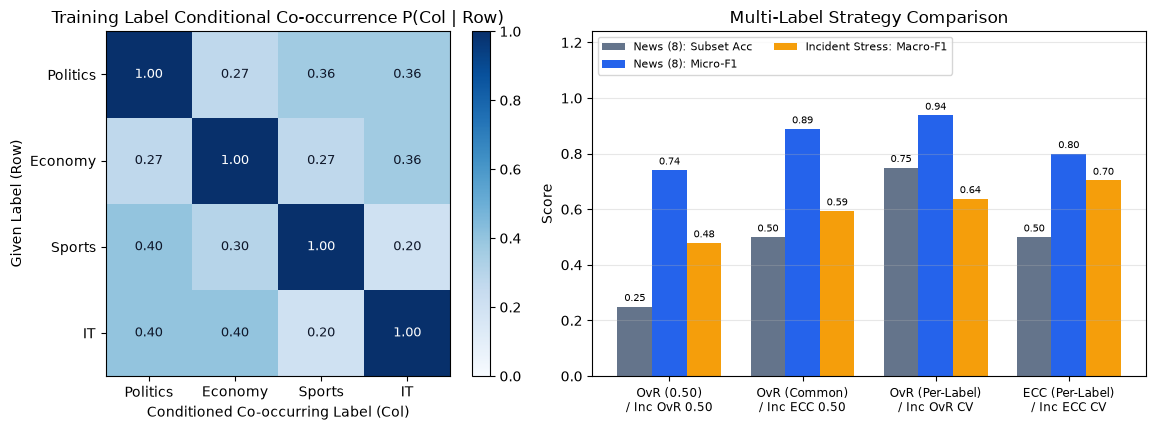

In [6]:
# 可視化: 条件付き共起ヒートマップ & 手法比較（すべて英語ラベル）
fig, axes = plt.subplots(1, 2, figsize=(12.6, 4.4))

# Panel 1: News Training Label Conditional Co-occurrence P(Col | Row)
en_labels = ["Politics", "Economy", "Sports", "IT"]
im = axes[0].imshow(cond_cooc, cmap="Blues", vmin=0.0, vmax=1.0)
axes[0].set_xticks(np.arange(4), en_labels)
axes[0].set_yticks(np.arange(4), en_labels)
axes[0].set_xlabel("Conditioned Co-occurring Label (Col)")
axes[0].set_ylabel("Given Label (Row)")
axes[0].set_title("Training Label Conditional Co-occurrence P(Col | Row)")
for r in range(4):
    for c in range(4):
        val = cond_cooc[r, c]
        txt_color = "white" if val >= 0.55 else "#0f172a"
        axes[0].text(c, r, f"{val:.2f}", ha="center", va="center", color=txt_color, fontsize=9.5)
fig.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)

# Panel 2: Multi-Label Strategy Comparison (8-sample test vs Incident Co-occ Stress Test)
methods_en = ["OvR (0.50)", "OvR (Common)", "OvR (Per-Label)", "ECC (Per-Label)"]
sub_vals = [r_ovr_050_8["Subset Accuracy"], r_ovr_com_8["Subset Accuracy"], r_ovr_per_8["Subset Accuracy"], r_ecc_per_8["Subset Accuracy"]]
mic_vals = [r_ovr_050_8["Micro-F1"], r_ovr_com_8["Micro-F1"], r_ovr_per_8["Micro-F1"], r_ecc_per_8["Micro-F1"]]
inc_mac_vals = [r_inc_ovr_050["Macro-F1"], r_inc_ecc_050["Macro-F1"], r_inc_ovr_per["Macro-F1"], r_inc_ecc_per["Macro-F1"]]

x = np.arange(4)
w = 0.26
axes[1].bar(x - w, sub_vals, width=w, color="#64748b", label="News (8): Subset Acc")
axes[1].bar(x, mic_vals, width=w, color="#2563eb", label="News (8): Micro-F1")
axes[1].bar(x + w, inc_mac_vals, width=w, color="#f59e0b", label="Incident Stress: Macro-F1")

for xi, (s, m, imf) in enumerate(zip(sub_vals, mic_vals, inc_mac_vals)):
    axes[1].text(xi - w, s + 0.02, f"{s:.2f}", ha="center", fontsize=7.5)
    axes[1].text(xi, m + 0.02, f"{m:.2f}", ha="center", fontsize=7.5)
    axes[1].text(xi + w, imf + 0.02, f"{imf:.2f}", ha="center", fontsize=7.5)

axes[1].set_xticks(x, ["OvR (0.50)\n/ Inc OvR 0.50", "OvR (Common)\n/ Inc ECC 0.50", "OvR (Per-Label)\n/ Inc OvR CV", "ECC (Per-Label)\n/ Inc ECC CV"], fontsize=8.5)
axes[1].set_ylim(0.0, 1.24)
axes[1].set_ylabel("Score")
axes[1].set_title("Multi-Label Strategy Comparison")
axes[1].legend(loc="upper left", ncol=2, fontsize=8)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### 第3節のまとめ

- **弱相関データ（ニュース見出し）ではラベル別 CV 閾値＋フォールバックが最適**: `train_samples` の条件付き共起確率 $P(\text{Col} \mid \text{Row})$ は `0.200〜0.400` 程度とほぼ独立に近いため、ラベルごとの閾値最適化（`政治: 0.40, 経済: 0.50, スポーツ: 0.35, IT: 0.30`）によって 8 件テストの Subset Accuracy が **`0.500` → `0.750`**、Micro-F1 が **`0.889` → `0.938`** へ大きく向上します。また拡張 16 件テストでは標準閾値 `0.50` のゼロ予測事例をフォールバックで救済できました。
- **強共起データ（運用インシデント分類）では `ECC` が優位**: `障害発生`・`緊急対応`・`顧客影響` のように条件付き共起確率が高いタスクでは、ラベル間依存を利用できる **`Ensemble of Classifier Chains (ECC)`** が `OneVsRest` を上回る性能を示します。タスクの共起構造に応じて「独立 + ラベル別閾値調整」と「Classifier Chains」を使い分ける設計が重要です。